## Distribuição de probabilidade
## Livro de referência: Livro "Practical statistics for data scientists + 50+ essential concepts using R and Pyhton" - Bruce, Bruce & Gedeck

## Informações gerais

In [1]:
# erro estatístico - reflexo natural da variabilidade de uma determinada variável
# viés estatístico - é um erro sistemático, que empurra os dados em uma direção constantemente
    # viés de seleção - os dados que "sobreviveram"; a análise não considera dados amplos
    # seleção de autoviés - a análise é feita por extremos; ex: a análise de comentários de restaurantes onde só quem detestou a comida escreveu algo
    # data snooping - "tortura de dados", padrões e respostas que os analistas encontram após análise extensiva dos dados

In [2]:
# regressão à média
# fênomeno estatístico em que as amostras tendem a retornar ao resultado médio, porém este resultado costuma ser mascarado por intervenções externas
# ex: o chefe que interviu nos resultados de uma equipe que baixaram em um mês e no mês seguinte retornam à média histórica

In [3]:
# amostragem aleatória
# processo de seleção estruturado de forma a que nenhum subgrupo da população seja excluído durante as análises
# visa eliminar o erro de viés estatístico, mantendo somente erros aleatórios
# ex: em uma pesquisa eleitoral, é importante manter os diversos subgrupos que representam a sociedade, de forma a que não haja enviesamento em função de
# identificação com campo político

In [4]:
# amostragem estratificada
# seleção de amostra por subgrupo para entender o comportamento e representatividade de cada um
# ex: subgrupo por gênero, idade etc em uma pesquisa eleitoral

In [5]:
# distribuição de dados - como os valores individuais se distribuem
# distribuição amostral de uma estatística - distribuição obtida caso se calculasse uma estatística em amostras diferentes dentro da mesma população
    # ex: calcular a média salarial em grupos de 50 pessoas dentro de uma mesma população
# a distribuição amostral tende a ser mais estreita - é mais estável
# tende a ser mais normal (em formato de sino) do que os dados originais - Teora Central do Limite
# quanto maior a amostra, mais estreita e normal ela fica

In [6]:
# Erro padrão
# medida que captura a variabilidade da distribuição amostral
# tecnicamente, é o desvio padrão da distribuição amostral de uma estatística
# se eu repetir o cálculo da estatística em amostras diferentes do mesmo tamanho extraído da mesma população, a variabilidade gira em torno de um valor
# populacional, com desvio padrão; esse é o desvio padrão
# quando maior o tamanho da amostra, menor o erro padrão
# SE = desvio padrão / raiz da amostra

In [7]:
# importações
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import math

In [8]:
jobs = pd.read_csv("jobs_in_data_2024.csv",sep=",")

In [9]:
# Reconhecimento inicial
jobs.shape
jobs.info()
jobs.head()
jobs.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


,work_year,salary,salary_in_usd
count,14199.000000,14199.000000,14199.00000
mean,2023.110501,149057.514262,149472.04944
std,0.686929,64932.044143,64379.26016
min,2020.000000,14000.000000,15000.00000
25%,2023.000000,102150.000000,104000.00000
50%,2023.000000,142000.000000,142000.00000
75%,2024.000000,185900.000000,185900.00000
max,2024.000000,450000.000000,450000.00000


In [10]:
# Reconhecimento inicial
jobs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14199 entries, 0 to 14198
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   work_year           14199 non-null  int64 
 1   experience_level    14199 non-null  object
 2   employment_type     14199 non-null  object
 3   job_title           14199 non-null  object
 4   salary              14199 non-null  int64 
 5   salary_currency     14199 non-null  object
 6   salary_in_usd       14199 non-null  int64 
 7   employee_residence  14199 non-null  object
 8   work_setting        14199 non-null  object
 9   company_location    14199 non-null  object
 10  company_size        14199 non-null  object
 11  job_category        14199 non-null  object
dtypes: int64(3), object(9)
memory usage: 1.3+ MB


In [11]:
# Reconhecimento inicial
jobs.head()

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling


In [12]:
# Reconhecimento inicial
jobs["salary"].describe()

count     14199.000000
mean     149057.514262
std       64932.044143
min       14000.000000
25%      102150.000000
50%      142000.000000
75%      185900.000000
max      450000.000000
Name: salary, dtype: float64

In [13]:
# erro padrão
# desvio padrão da amostra / raiz do tamanho da amostra
jobs["salary"].std() / np.sqrt(len(jobs["salary"]))

544.9167975620591

In [14]:
# intervalo de confiança
# forma de lidar com a variabilidade de uma amostragem
# ex: com 95% de confiança, a MÉDIA SALARIAL DA POPULAÇÃO de DS está entre $148.413 e $150.531
# Importante: a leitura correta é que se repetirmos a amostragem 100 vezes e construirmos o IC em cada uma,
#     aprox. 95 desses intervalos vão conter a verdadeira média populacional
# NÃO significa: há 95% de chance de a média estar nesse intervalo específico
# O intervalo ou contém a média verdadeira ou não contém — é 0 ou 1
# O 95% descreve o PROCEDIMENTO, não esse intervalo em particular

In [15]:
# Qualidade de dados é a fundação. Quantidade é o acabamento

In [16]:
# DISTRIBUIÇÃO ESTATÍSTICA

loans_income = pd.read_csv("loans_income.csv",sep=",") #banco de dados bruto
sample_data = pd.DataFrame({"income":loans_income["x"].sample(1000).squeeze(),"type":"Sampling data"}) #tomei amostragem aleatória de 
# 1000 amostras dentro da amostra principal

sample_mean_05 = pd.DataFrame({"income":[loans_income["x"].sample(5).mean() for _ in range (1000)],"type": "Mean of 5"}) #sample de 5 amostras 
# repetido 1000 vezes

sample_mean_20 = pd.DataFrame({"income":[loans_income["x"].sample(20).mean() for _ in range (1000)],"type":"Mean of 20"})

# Importante
# O _ é uma convenção do Python para dizer "preciso de uma variável de controle para o loop funcionar, 
# mas não vou usá-la em nenhum momento". É só um sinal para quem lê o código: "esse contador não importa, o que importa é a repetição"

results = pd.concat([sample_data,sample_mean_05,sample_mean_20]) #juntando todos os df de sample em um df só, para construção de gráficos

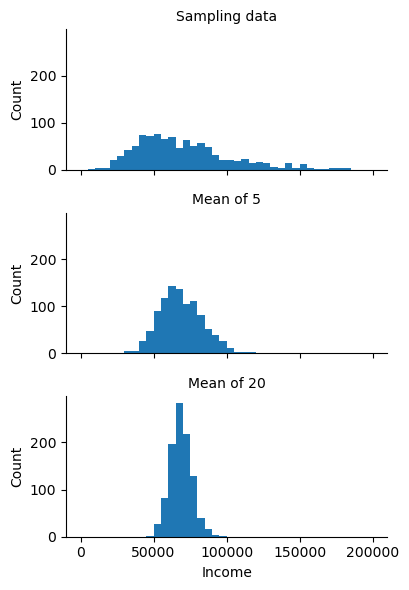

In [17]:
# gráfico para análise de distribuição amostral e distribuição estatística

g = sns.FacetGrid(results,col="type",col_wrap = 1, height = 2, aspect = 2)
g.map(plt.hist,"income",range = [0,200000], bins = 40)
g.set_axis_labels ("Income","Count")
g.set_titles("{col_name}")

In [18]:
# Teorema do Limite Central
# A distribuição das médias calculadas a partir de várias amostras (de uma amostra maior) terá a forma de uma curva normal (formato de sino), mesmo que a população não seja distribuída normalmente,
# desde que a amostra seja grande o suficiente
# O Teorema do Limite Central permite fórmulas para aproximação da distribuição normal, como a forma de distribuição-t

In [19]:
# Bootstrap
# técnica de reamostragem, onde as amostras usadas usam de reposição
# Não envolve a premissa de que os dados ou estatísticas amostrais possuam distribuição normal
# A amostra original é reamostrada várias vezes COM REPOSIÇÃO para estimar a distribuição amostral de uma estatística

# Algoritmo bootstrap
# 1- Tire uma reamostrage da amostra original COM REPOSIÇÃO, do mesmo tamanho
# 2- Calcule a estatística de interesse nessa reamostrage e grave
# 3- Repita os passos 1 e 2 R vezes (R arbitrário, tipicamente 1000 a 10000)
# 4- Use os R valores gravados para:
#    - calcular o erro padrão (std dos R valores)
#    - calcular o viés (média dos R valores - estatística original)
#    - construir intervalo de confiança (percentis 2.5% e 97.5%)
#    - plotar histograma para visualizar a distribuição amostral

In [20]:
# Bootstrap usando o método resample de scikit-learn
from sklearn.utils import resample
results = []
for nrepeat in range (1000):
    sample = resample(loans_income["x"])
    results.append(sample.median())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {loans_income['x'].median()}")
print(f"bias: {results.mean() - loans_income["x"].median()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 62000.0
bias: -83.46949999999924
std. error: 227.2806642019275


In [21]:
# Resumo de bootstrap
# O que é — reamostrage com reposição para estimar a distribuição amostral de qualquer estatística sem premissa de normalidade.
# Como funciona — sorteia R amostras da original com reposição, calcula a estatística em cada uma, usa as R estatísticas para medir variabilidade.
# O que entrega — erro padrão, viés e intervalo de confiança do estimador.

In [22]:
results = []
for nrepeat in range (1000):
    sample = resample(jobs["salary"])
    results.append(sample.mean())
results = pd.Series(results)
print("Bootstrap Statistics:")
print(f"original: {jobs["salary"].mean()}")
print (f"bootstrap mean: {results.mean()}")
print(f"bias: {results.mean() - jobs["salary"].mean()}") #mede o viés do amostrador
print(f"std. error: {results.std()}")

Bootstrap Statistics:
original: 149057.5142615677
bootstrap mean: 149037.85685991973
bias: -19.65740164797171
std. error: 543.063268778383


In [23]:
jobs

,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,work_setting,company_location,company_size,job_category
0,2024,Entry-level,Freelance,Applied Data Scientist,30000,USD,30000,United Kingdom,Remote,United Kingdom,M,Data Science and Research
1,2024,Executive,Full-time,Business Intelligence,230000,USD,230000,United States,In-person,United States,M,BI and Visualization
2,2024,Executive,Full-time,Business Intelligence,176900,USD,176900,United States,In-person,United States,M,BI and Visualization
3,2024,Senior,Full-time,Data Architect,171210,USD,171210,Canada,In-person,Canada,M,Data Architecture and Modeling
4,2024,Senior,Full-time,Data Architect,92190,USD,92190,Canada,In-person,Canada,M,Data Architecture and Modeling
...,...,...,...,...,...,...,...,...,...,...,...,...
14194,2021,Senior,Full-time,Data Specialist,165000,USD,165000,United States,Remote,United States,L,Data Management and Strategy
14195,2020,Senior,Full-time,Data Scientist,412000,USD,412000,United States,Remote,United States,L,Data Science and Research
14196,2021,Mid-level,Full-time,Principal Data Scientist,151000,USD,151000,United States,Remote,United States,L,Data Science and Research
14197,2020,Entry-level,Full-time,Data Scientist,105000,USD,105000,United States,Remote,United States,S,Data Science and Research


## Distribuição normal

In [25]:
# Distribuição normal - os valores do eixo x são expressas em termos de desvios-padrão da média
# Parâmetros: média (em torno da qual todas as medidas se espalham) e desvio padrão (que diz quão espalhada é a distribuição)
# Erro - diferença entre um dado (ponto) e o valor previsto ou médio
# Padronizar - Subtrair a média e dividir pelo desvio padrão (z-score)
# z-score: o resultado de se padronizar um dado individual. Z = (x − μ) / σ
    # coloca tudo na mesma língua: desvio padrão
    # permite comparar resultados dentro de amostragens diferentes
# distribuição normal: uma distribuição com média = 0 e desvio padrão = 1
    # 68% dos dados caem dentro de μ ± 1σ
    # 95% dos dados caem dentro de μ ± 2σ
    # 99.7% dos dados caem dentro de μ ± 3σ
    # Regra empírica ou regra 68-95-99.7
# QQ-plot: um gráfico que mostra o que perto uma distribuição amostral é em relação a uma distribuição especial (e.g. a distribuição normal) # Teste de Ouro!!!!
# Fundamental: a normal é simétrica. Quando a variável não pode ser negativa, ou quando tem uma causa longa assimétrica,
# em geral é necessário realizar uma transformação logarítmica: se x não é normal, log(x) pode ser - distribuição log normal

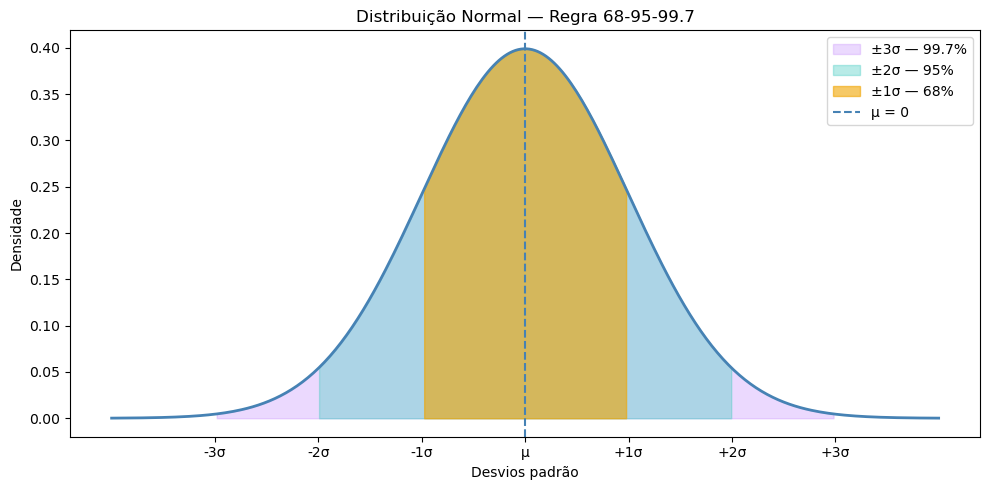

In [26]:
# Distribuição normal
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# normal padrão
x = np.linspace(-4, 4, 300)
y = stats.norm.pdf(x, 0, 1)

fig, ax = plt.subplots(figsize=(10, 5))

# curva completa
ax.plot(x, y, color="steelblue", linewidth=2)

# regiões — ordem do maior para o menor
ax.fill_between(x, y, where=(x >= -3) & (x <= 3),
                color="#c084fc", alpha=0.3, label="±3σ — 99.7%")
ax.fill_between(x, y, where=(x >= -2) & (x <= 2),
                color="#4ecdc4", alpha=0.4, label="±2σ — 95%")
ax.fill_between(x, y, where=(x >= -1) & (x <= 1),
                color="#f0a500", alpha=0.6, label="±1σ — 68%")

# linha da média
ax.axvline(0, color="steelblue", linewidth=1.5,
           linestyle="--", label="μ = 0")

# marcações no eixo x
ax.set_xticks([-3, -2, -1, 0, 1, 2, 3])
ax.set_xticklabels(["-3σ", "-2σ", "-1σ", "μ", "+1σ", "+2σ", "+3σ"])

ax.set_xlabel("Desvios padrão")
ax.set_ylabel("Densidade")
ax.set_title("Distribuição Normal — Regra 68-95-99.7")
ax.legend()
plt.tight_layout()
plt.show()

((array([-2.46203784, -2.12570747, -1.93122778, -1.79044653, -1.67819304,
         -1.58381122, -1.50174123, -1.42869743, -1.36256869, -1.30191411,
         -1.24570419, -1.19317644, -1.14374949, -1.09696931, -1.05247413,
         -1.00997067, -0.96921765, -0.93001393, -0.89218993, -0.85560121,
         -0.82012357, -0.78564937, -0.75208458, -0.71934648, -0.68736185,
         -0.65606548, -0.62539893, -0.59530962, -0.56574992, -0.53667655,
         -0.50804994, -0.47983378, -0.45199463, -0.42450149, -0.39732558,
         -0.37044003, -0.34381966, -0.31744076, -0.29128096, -0.26531902,
         -0.23953472, -0.21390872, -0.18842244, -0.16305799, -0.13779803,
         -0.1126257 , -0.08752455, -0.06247843, -0.03747145, -0.01248789,
          0.01248789,  0.03747145,  0.06247843,  0.08752455,  0.1126257 ,
          0.13779803,  0.16305799,  0.18842244,  0.21390872,  0.23953472,
          0.26531902,  0.29128096,  0.31744076,  0.34381966,  0.37044003,
          0.39732558,  0.42450149,  0.

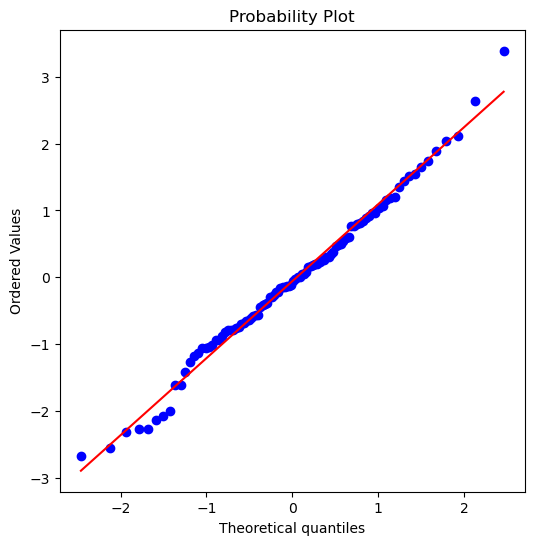

In [45]:
# QQ-plot usando o método scipy.stats.probplot

fig, ax = plt.subplots(figsize=(6,6))
norm_sample = stats.norm.rvs(size=100)
stats.probplot(norm_sample,plot=ax)

((array([-3.89640555, -3.67593223, -3.55510109, ...,  3.55510109,
          3.67593223,  3.89640555]),
  array([ 14000,  15000,  15000, ..., 448000, 450000, 450000], dtype=int64)),
 (64074.00386119124, 149057.5142615677, 0.9865631608062654))

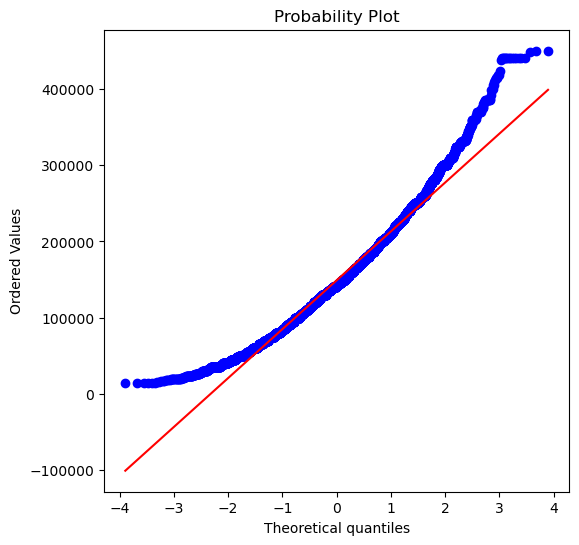

In [48]:
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(jobs["salary"],plot=ax)

((array([-3.89640555, -3.67593223, -3.55510109, ...,  3.55510109,
          3.67593223,  3.89640555]),
  array([ 9.54681261,  9.61580548,  9.61580548, ..., 13.01254851,
         13.01700286, 13.01700286])),
 (0.47730221009582924, 11.807001970375556, 0.9846413606884492))

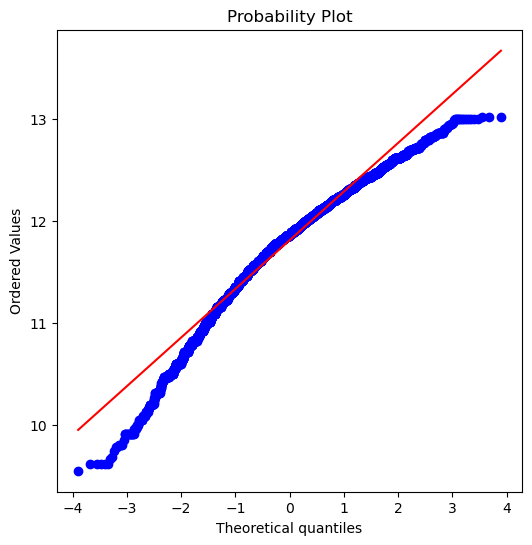

In [47]:
# transformação logarítmica
n_log = np.log(jobs["salary"])

# plotar QQ-plot
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(n_log,plot=ax)

0        10.308953
1        12.345835
2        12.083340
3        12.050646
4        11.431607
           ...    
14194    12.013701
14195    12.928779
14196    11.925035
14197    11.561716
14198    11.512925
Name: salary, Length: 14199, dtype: float64

In [49]:
teen_mental = pd.read_csv("Teen_Mental_Health_Dataset.csv",sep=",")

In [56]:
teen_mental["daily_social_media_hours"].describe()

count    1200.000000
mean        4.536667
std         2.029599
min         1.000000
25%         2.800000
50%         4.500000
75%         6.300000
max         8.000000
Name: daily_social_media_hours, dtype: float64

((array([-3.24978775, -2.98852082, -2.84297384, ...,  2.84297384,
          2.98852082,  3.24978775]),
  array([1., 1., 1., ..., 8., 8., 8.])),
 (1.9884413701533752, 4.536666666666668, 0.9778089285447285))

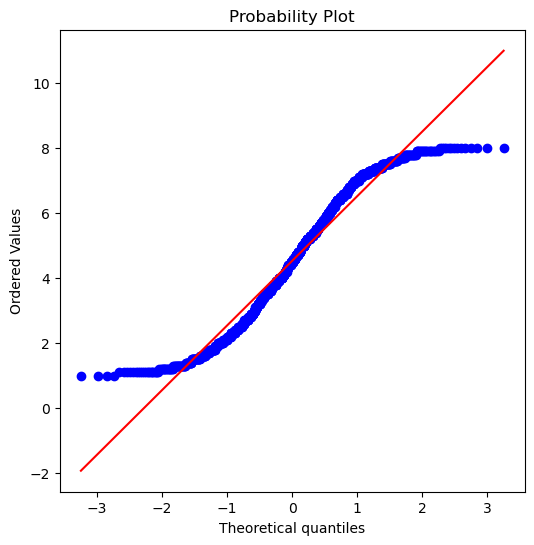

In [58]:
fig, ax = plt.subplots(figsize = (6,6))
stats.probplot(teen_mental["daily_social_media_hours"], plot = ax)

((array([-3.24978775, -2.98852082, -2.84297384, ...,  2.84297384,
          2.98852082,  3.24978775]),
  array([0.        , 0.        , 0.        , ..., 2.07944154, 2.07944154,
         2.07944154])),
 (0.5197577818634459, 1.3860919018116722, 0.9622745185122831))

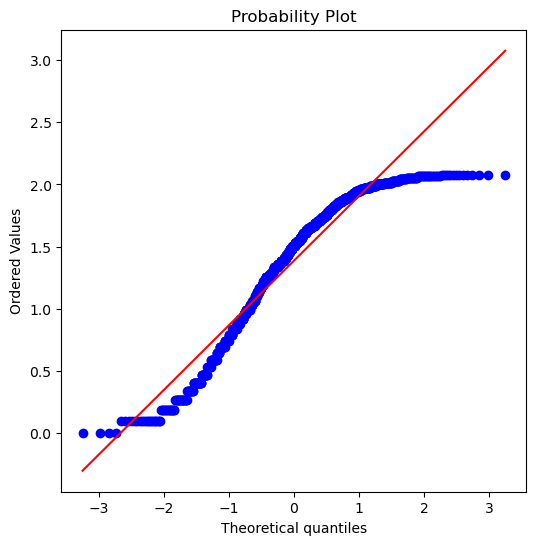

In [65]:
th_n_plot = np.log(teen_mental["daily_social_media_hours"])

fig,ax = plt.subplots(figsize = (6,6))
stats.probplot(th_n_plot, plot = ax)

0       2.066863
1       0.641854
2       0.262364
3       2.001480
4       1.547563
          ...   
1195    1.916923
1196    0.832909
1197    0.530628
1198    1.360977
1199    1.547563
Name: daily_social_media_hours, Length: 1200, dtype: float64

## Distribuição Cauda-Longa

In [95]:
# Distribuição de Cauda-Longa - descreve uma situação em que a maioria dos valores são (relativamente) pequenos, mas alguns valores são extraordinariamente grandes, e esses gigantes importam muito
# cauda: porção da curva onde valores relativamente extermos ocorrem a baixa frequência
# assimetria: onde uma das caudas é maior do que a outra
# as caudas correspondem a ambos extermos: pequeno e grande
# A maioria dos dados não é normal, e assumir uma distribuição norma, pode levar a subestimar valores extremos ("cisnes negros")

((array([-3.66693296, -3.43349504, -3.3049302 , ...,  3.3049302 ,
          3.43349504,  3.66693296]),
  array([-9.33142848, -3.7985726 , -3.06999973, ...,  3.63571546,
          4.13857274,  4.29285427])),
 (0.3141665090484467, 0.0056458357374863065, 0.7640314545417974))

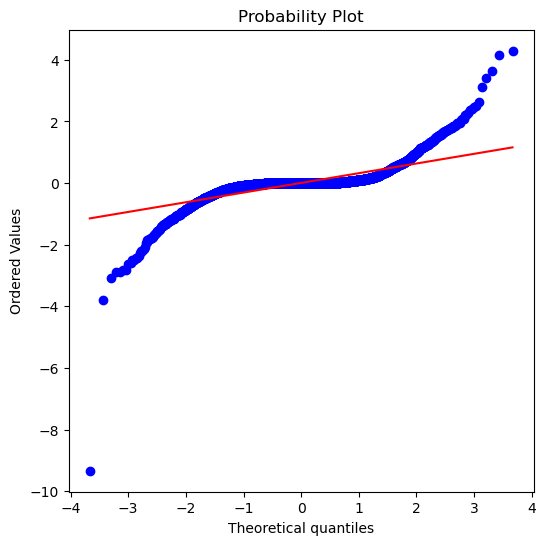

In [81]:
# estudo de caso: retorno diário das ações da NETFLIX

sp500_px = pd.read_csv("sp500_data.csv",sep=",")
nflx = sp500_px.NFLX
fix, ax = plt.subplots(figsize = (6,6))
stats.probplot(nflx,plot = ax)

# observe que os pontos ficam mais perto da linha normal entre -1 e +1 desvio-padrão, o que Tukey chama de "normal no meio" (eixo x)

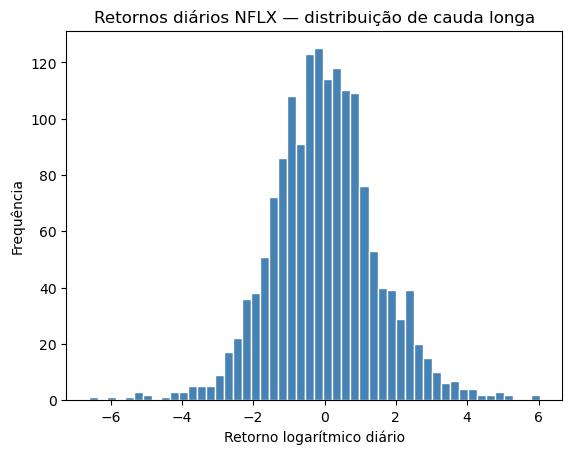

In [94]:
# calcula retornos diários
nflx = sp500_px["NFLX"]
nflx = nflx[nflx > 0]
nflx_retornos = pd.Series(np.diff(np.log(nflx)))

# histograma dos retornos
plt.hist(nflx_retornos, bins=50, edgecolor="white", color="steelblue")
plt.title("Retornos diários NFLX — distribuição de cauda longa")
plt.xlabel("Retorno logarítmico diário")
plt.ylabel("Frequência")
plt.show()

In [89]:
nflx.describe()

count    5647.000000
mean        0.005646
std         0.410986
min        -9.331428
25%        -0.021429
50%         0.000000
75%         0.020714
max         4.292854
Name: NFLX, dtype: float64

## Distribuição t-student

In [97]:
# utilizada quando se tem amostras pequenas
# possui forma semelhante à normal, porém com caudas mais pesadas, maiores, para se trabalhar com a incerteza própria da amostragem pequena
# parâmetro que controla o formato: graus de liberdade, que na prática é o número de amostras menos um (n-1)
    # quanto menor o n, mais conservadora a distribuição e maiores as caudas; quanto maior n, menores as causas e mais a t converge para a normal
    # para n = 30, é difícil distingur, a olho nu, a normal da t; com n=5 a diferença é enorme

In [ ]:
# o valor de desvio-padrão que captura 97,5% da distribuição varia em função dos graus de liberdade

In [100]:
from scipy import stats

for gl in [2, 5, 10, 20, 30, 100]:
    t_crit = stats.t.ppf(0.975, df=gl)
    print(f"gl={gl:>4}  →  t crítico = {t_crit:.4f}")

gl=   2  →  t crítico = 4.3027
gl=   5  →  t crítico = 2.5706
gl=  10  →  t crítico = 2.2281
gl=  20  →  t crítico = 2.0860
gl=  30  →  t crítico = 2.0423
gl= 100  →  t crítico = 1.9840


In [ ]:
# Quando usar? - em testagens estatísticas
    # Teste t para uma amostra
    # Teste t para duas amostras independentes
    # Coeficiente de regressão

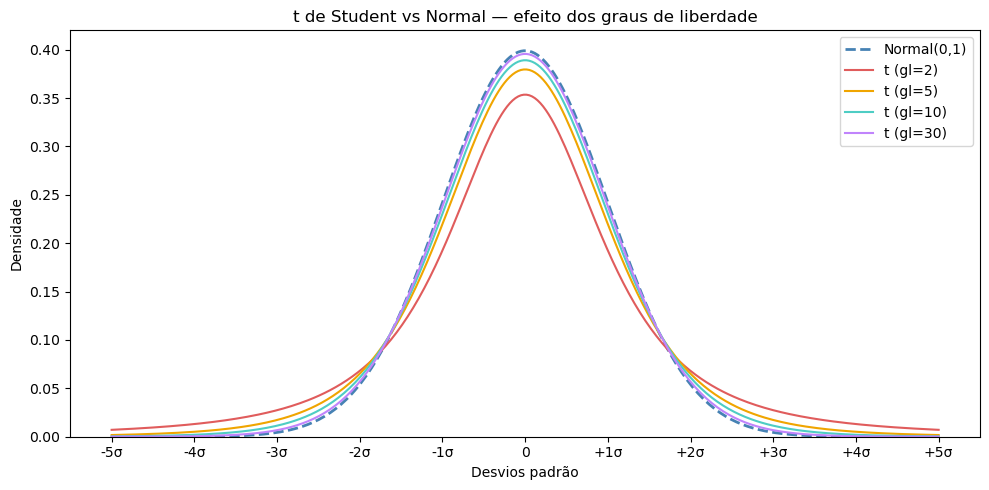

In [102]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

x = np.linspace(-5, 5, 300)

fig, ax = plt.subplots(figsize=(10, 5))

# normal padrão — referência
ax.plot(x, stats.norm.pdf(x), color="steelblue",
        linewidth=2, linestyle="--", label="Normal(0,1)")

# t com diferentes graus de liberdade
for gl, cor in [(2, "#e05c5c"), (5, "#f0a500"),
                (10, "#4ecdc4"), (30, "#c084fc")]:
    ax.plot(x, stats.t.pdf(x, df=gl), linewidth=1.5,
            color=cor, label=f"t (gl={gl})")

# eixo x com marcações explícitas incluindo -3,-2,-1,0,1,2,3
ax.set_xticks([-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5])
ax.set_xticklabels(["-5σ", "-4σ", "-3σ", "-2σ", "-1σ",
                    "0", "+1σ", "+2σ", "+3σ", "+4σ", "+5σ"])

ax.set_xlabel("Desvios padrão")
ax.set_ylabel("Densidade")
ax.set_title("t de Student vs Normal — efeito dos graus de liberdade")
ax.legend()
ax.set_ylim(0, 0.42)
plt.tight_layout()
plt.show()

In [ ]:
# A t de Student é a distribuição da honestidade intelectual.
# Ela diz: "com amostra pequena, você sabe menos do que pensa — e seu intervalo de confiança precisa refletir isso".
# À medida que você coleta mais dados, a t se torna cada vez mais parecida com a normal — a incerteza diminui organicamente com o tamanho da amostra
# no contexto de data science moderno, com amostras grandes e bootstrap disponível, a t não é tão central quanto nos livros clássicos.
# Mas você vai encontrá-la em todo output de regressão, em todo A/B test, em toda comparação de médias. Saber o que ela significa é obrigatório